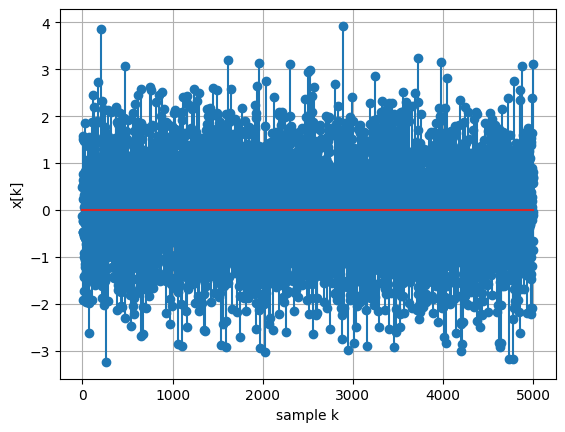

expected weights [ 1.         -0.25        0.5625     -0.265625    0.34765625 -0.21972656
  0.22875977 -0.16705322  0.15614319 -0.12256241]
learned weights [ 0.9719177  -0.23719315  0.56370423 -0.24939719  0.3356926  -0.22519669
  0.23271249 -0.17522089  0.16260358 -0.12101792]


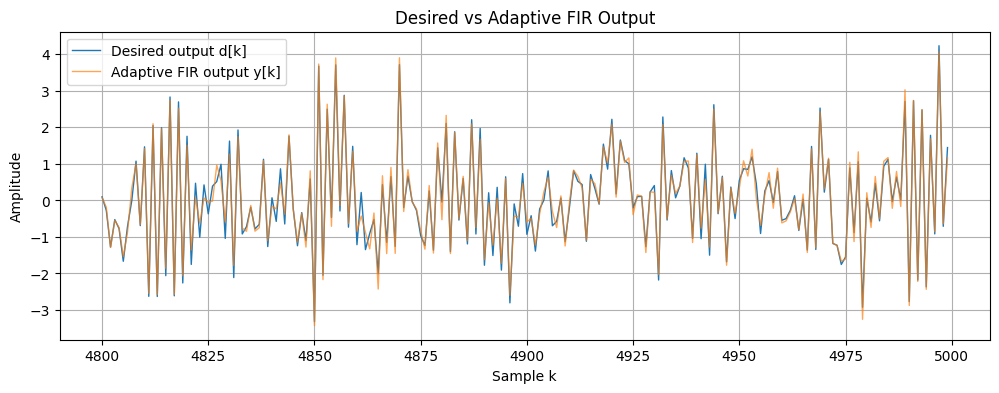

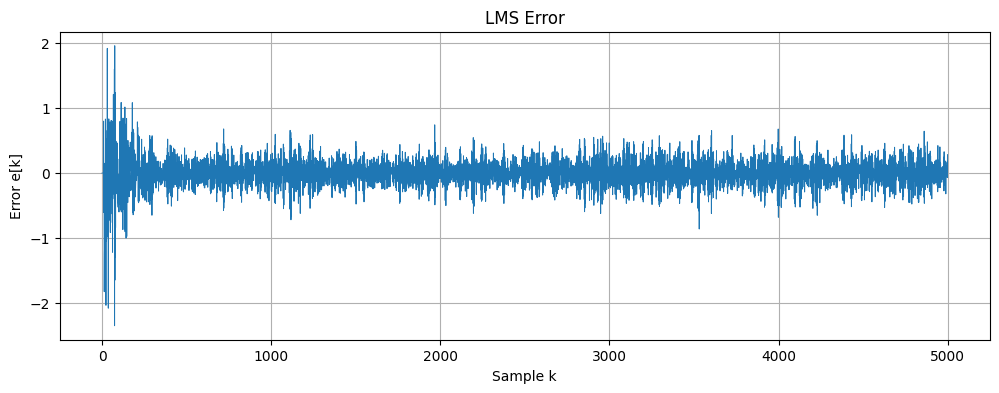

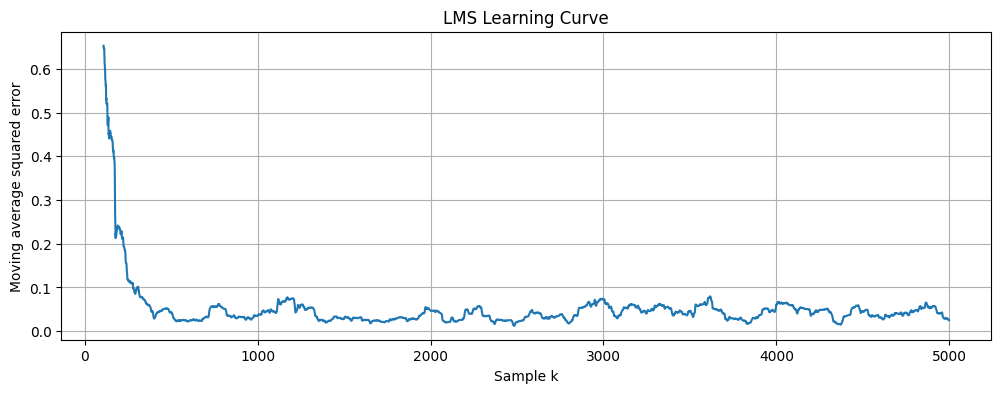

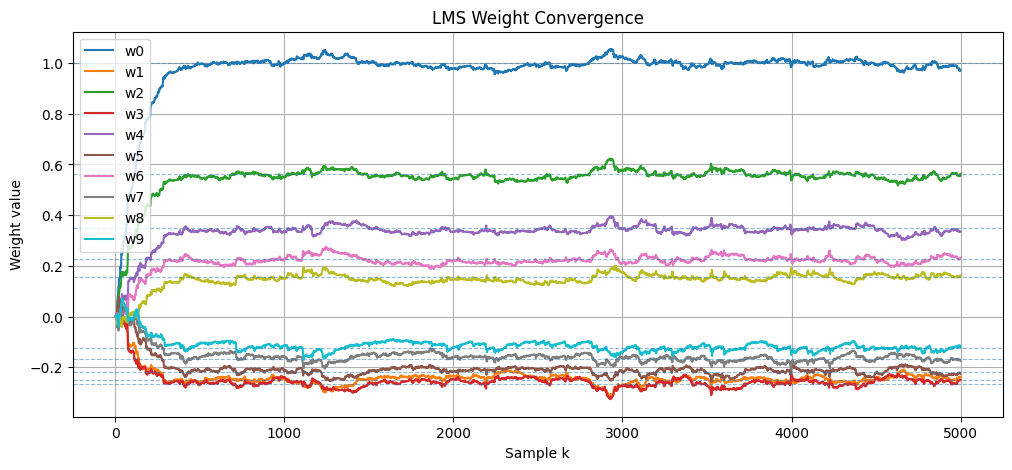

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter

LEN = 5000
N = 10 #number of taps
x = np.random.seed(42)
x = np.random.normal(0, 1, LEN) #scale=1, std deviation, giving unit variance
x_k = 0
w_history = np.zeros((LEN,N))
w = np.zeros(N) # all zeroes to start
y = np.zeros(LEN)
d = np.zeros(LEN)
e = np.zeros(LEN)
plt.stem(x)
plt.xlabel("sample k")
plt.ylabel("x[k]")
plt.grid()
plt.show()

#H(z) = 1 / (1+0.25z^-1 - 0.5z^-2)
#rearrange for difference equation coeffs
#d[k] = x[k] + 0.25d[k-1] - 0.5d[k-2]
#d[k] - 0.25d[k-1] + 0.5d[k-2] = x[k]

#generate the system by implementing the filter
# y = lfilter([1], [1,0.25, -0.5],x)


#generate the filter coeffs vector w[k]



#w(k+1) = w[k] + 2*mu*e[k] * x[k]
#w[k] is a vector of koefficients
#x[k] is a signal vector, same N length as w[k], containing the latest samples

MU = 0.005

# for k in range(LEN):
#     #for every iteration:
#     #calculate d[k] (cases to ensure sample bounds)
#     d[k] = x[k] 
#     if k >= 1:
#         d[k] -= 0.25*y[k-1]
#     if k >= 2:
#         d[k] += 0.5*y[k-2]
d = lfilter([1], [1, 0.25, -0.5], x)

for k in range(N-1, len(x)):
    x_k = x[k-N+1:k+1][::-1]

    #calculate y[k] (FIR)
    y[k] = np.dot(x_k, w)

    #calculate error e[k] = d[k]-y[k]
    e[k] = d[k] - y[k]
    #update the weights
    w = w + 2 * MU * e[k] * x_k

    w_history[k] = w
    #go again


#calculate FIR coefficients with impulse response
impulse = np.zeros(N)
impulse[0] = 1
w_expected = lfilter([1], [1, 0.25, -0.5],impulse)

print("expected weights", w_expected)
print("learned weights", w)


plt.figure(figsize=(12, 4))

# Show the final 200 samples after adaptation
start = LEN - 200

plt.plot(np.arange(start, LEN), d[start:],
         label="Desired output d[k]", linewidth=1)

plt.plot(np.arange(start, LEN), y[start:],
         label="Adaptive FIR output y[k]", linewidth=1, alpha=0.7)

plt.xlabel("Sample k")
plt.ylabel("Amplitude")
plt.title("Desired vs Adaptive FIR Output")
plt.legend()
plt.grid()
plt.show()

# ------------------------------------------------
# 8. Plot LMS error
# ------------------------------------------------

plt.figure(figsize=(12, 4))

plt.plot(e, linewidth=0.7)

plt.xlabel("Sample k")
plt.ylabel("Error e[k]")
plt.title("LMS Error")
plt.grid()
plt.show()

# ------------------------------------------------
# 9. Plot smoothed squared error
# ------------------------------------------------

window = 100

mse = np.convolve(e[N-1:]**2,
                  np.ones(window) / window,
                  mode="valid")

plt.figure(figsize=(12, 4))

plt.plot(np.arange(N-1 + window-1, LEN), mse)

plt.xlabel("Sample k")
plt.ylabel("Moving average squared error")
plt.title("LMS Learning Curve")
plt.grid()
plt.show()

# ------------------------------------------------
# 10. Plot weight convergence
# ------------------------------------------------

plt.figure(figsize=(12, 5))

for i in range(N):
    plt.plot(w_history[:, i], label=f"w{i}")

    # Reference line for corresponding IIR impulse coefficient
    plt.axhline(w_expected[i],
                linestyle="--",
                linewidth=0.8,
                alpha=0.5)

plt.xlabel("Sample k")
plt.ylabel("Weight value")
plt.title("LMS Weight Convergence")
plt.legend()
plt.grid()
plt.show()

